<table width="100%">
<tr>
<td width="16%" align="left"><img src="reporte/logo_uach.png" width="110"></td>
<td align="center"><h2>Universidad Autónoma de Chihuahua</h2><h3>Facultad de Ingeniería</h3><b>Maestría en Ingeniería en Computación</b></td>
<td width="16%" align="right"><img src="reporte/logo_fing.png" width="110"></td>
</tr>
</table>

<p align="center"><b><font size="6">Proyecto Final 2:<br>Predicción del Valor de Propiedades Inmobiliarias</font></b></p>

<p align="center"><i>Estadística Aplicada a la Investigación</i><br><b><i>Catedrático:</i></b> <i>Dr. José Saul De Lira Miramontes</i></p>

<p align="right"><b><i>Alumno:</i></b><br><b>345491</b> González Cardoza Jonahtan</p>

<p align="center">25 de noviembre de 2026</p>

## Introducción

| Dato | Detalle |
|---|---|
| **Alumno** | González Cardoza Jonahtan (matrícula 345491) |
| **Programa** | Maestría en Ingeniería en Computación, Facultad de Ingeniería, Universidad Autónoma de Chihuahua |
| **Materia** | Estadística Aplicada a la Investigación |
| **Catedrático** | Dr. José Saul De Lira Miramontes |
| **Entrega** | 25 de noviembre de 2026 |

**El caso.** Se busca un modelo que estime el precio de una vivienda a partir de sus características (superficie, terreno, recámaras, baños), de su ubicación y de indicadores económicos del área. Primero se usan herramientas estadísticas (descriptivos, correlación y regresión lineal) y después se comparan modelos de *machine learning*.

**Objetivos.**
1. Identificar los factores que más influyen en el precio con análisis de correlación.
2. Ajustar modelos de regresión lineal para entender las relaciones básicas.
3. Comparar modelos de *machine learning*.
4. Evaluar la precisión de cada modelo (MSE, RMSE, MAE, R²) y elegir el más adecuado.

**Datos.**
- `dataset/realtor-data.zip.csv`: anuncios de Realtor.com (Estados Unidos), 2,226,382 registros (se descarga de Kaggle; no viene en el repositorio porque pesa 179 MB). Se usan las casas **vendidas** entre octubre de 2021 y mayo de 2022.
- `dataset/indicadores_estados.csv`: por estado, PIB per cápita nominal 2025 (BEA y Census Bureau) y tasas de crimen violento y de homicidio por cada 100 mil habitantes 2024 (FBI, Uniform Crime Reporting).

**Fases:** (1) recolección y limpieza, (2) análisis exploratorio y correlación, (3) regresión lineal, (4) *machine learning*, (5) comparación de modelos y (6) archivos para el dashboard. Nivel de significancia: α = 0.05.

In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor

alpha = 0.05
seed = 42
os.makedirs("reporte/figuras", exist_ok=True)
os.makedirs("modelos", exist_ok=True)
sns.set_theme(style="whitegrid", font_scale=1.0)
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["savefig.facecolor"] = "white"
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

labels = {"price": "Precio (USD)",
          "house_size_m2": "Superficie (m²)",
          "lot_size_m2": "Terreno (m²)",
          "bed": "Recámaras",
          "bath": "Baños",
          "gdp_per_capita": "PIB per cápita (USD)",
          "violent_crime_rate": "Crimen violento (por 100 mil)",
          "homicide_rate": "Homicidios (por 100 mil)",
          "month_index": "Mes de venta (0 = oct 2021)",
          "zip_price_m2": "Precio por m² de la zona (USD)"}

## 1. Recolección y preparación de los datos
### 1.1 Datos originales

In [2]:
raw = pd.read_csv("dataset/realtor-data.zip.csv", dtype={"zip_code": str})
state_data = pd.read_csv("dataset/indicadores_estados.csv")

print("Registros y columnas del archivo original:", raw.shape)
print("\nEstado del anuncio:")
print(raw["status"].value_counts())
print("\nDatos faltantes por columna:")
print(raw.isna().sum())
raw.head()

Registros y columnas del archivo original: (2226382, 12)

Estado del anuncio:
status
for_sale          1389306
sold               812009
ready_to_build      25067
Name: count, dtype: int64

Datos faltantes por columna:
brokered_by         4533
status                 0
price               1541
bed               481317
bath              511771
acre_lot          325589
street             10866
city                1407
state                  8
zip_code             299
house_size        568484
prev_sold_date    734297
dtype: int64


,brokered_by,status,price,bed,bath,acre_lot,street,city,state,zip_code,house_size,prev_sold_date
0,"103,378.0000",for_sale,"105,000.0000",3.0000,2.0000,0.1200,"1,962,661.0000",Adjuntas,Puerto Rico,00601,920.0000,NaN
1,"52,707.0000",for_sale,"80,000.0000",4.0000,2.0000,0.0800,"1,902,874.0000",Adjuntas,Puerto Rico,00601,"1,527.0000",NaN
2,"103,379.0000",for_sale,"67,000.0000",2.0000,1.0000,0.1500,"1,404,990.0000",Juana Diaz,Puerto Rico,00795,748.0000,NaN
3,"31,239.0000",for_sale,"145,000.0000",4.0000,2.0000,0.1000,"1,947,675.0000",Ponce,Puerto Rico,00731,"1,800.0000",NaN
4,"34,632.0000",for_sale,"65,000.0000",6.0000,2.0000,0.0500,"331,151.0000",Mayaguez,Puerto Rico,00680,NaN,NaN


### 1.2 Limpieza
Pasos:
1. Solo casas **vendidas** (`status = sold`): su precio es el de una venta real, no el que pide el vendedor. En estas filas `prev_sold_date` es la fecha de la venta.
2. Quitar filas con datos faltantes en las variables del modelo y filas duplicadas.
3. Unir los indicadores por estado. Puerto Rico e Islas Vírgenes se quedan fuera porque no tienen datos del FBI.
4. Quitar valores imposibles o extremos: precio entre 50 mil y 5 millones de dólares, superficie entre 300 y 10,000 pies², de 1 a 10 recámaras y baños, terreno mayor que 0 y hasta 10 acres.
5. Quitar el 1 % más bajo y el 1 % más alto del precio por pie² (errores de captura, como una casa grande a 7 dólares el pie²).
6. Convertir unidades: pies² a m² (× 0.092903) y acres a m² (× 4,046.86).

In [3]:
steps = []
steps.append(("Archivo original", len(raw)))

houses = raw[raw["status"] == "sold"].copy()
steps.append(("Solo casas vendidas", len(houses)))

houses = houses.dropna(subset=["price", "bed", "bath", "acre_lot", "house_size", "state", "zip_code", "prev_sold_date"])
steps.append(("Sin datos faltantes", len(houses)))

houses = houses.drop_duplicates()
steps.append(("Sin duplicados", len(houses)))

houses = houses.merge(state_data, on="state", how="inner")
steps.append(("Con indicadores del estado", len(houses)))

houses = houses[houses["price"].between(50_000, 5_000_000)
                & houses["house_size"].between(300, 10_000)
                & houses["bed"].between(1, 10)
                & houses["bath"].between(1, 10)
                & (houses["acre_lot"] > 0) & (houses["acre_lot"] <= 10)]
steps.append(("Rangos válidos", len(houses)))

price_sqft = houses["price"] / houses["house_size"]
low_cut = price_sqft.quantile(0.01)
high_cut = price_sqft.quantile(0.99)
houses = houses[price_sqft.between(low_cut, high_cut)].copy()
steps.append(("Sin extremos de precio por pie²", len(houses)))

print(f"Límites del precio por pie²: {low_cut:.2f} a {high_cut:.2f} USD")
cleaning_table = pd.DataFrame(steps, columns=["Paso", "Registros"])
cleaning_table["Eliminados"] = (-cleaning_table["Registros"].diff()).fillna(0).astype(int)
cleaning_table

Límites del precio por pie²: 50.86 a 1077.77 USD


,Paso,Registros,Eliminados
0,Archivo original,2226382,0
1,Solo casas vendidas,812009,1414373
2,Sin datos faltantes,609776,202233
3,Sin duplicados,609776,0
4,Con indicadores del estado,609504,272
5,Rangos válidos,591566,17938
6,Sin extremos de precio por pie²,579734,11832


In [4]:
houses["house_size_m2"] = houses["house_size"] * 0.092903
houses["lot_size_m2"] = houses["acre_lot"] * 4046.86
houses["price_m2"] = houses["price"] / houses["house_size_m2"]
houses["sale_date"] = pd.to_datetime(houses["prev_sold_date"])
houses["month_index"] = (houses["sale_date"].dt.year - 2021) * 12 + houses["sale_date"].dt.month - 10
houses["bed"] = houses["bed"].astype(int)
houses["bath"] = houses["bath"].astype(int)

columns = ["price", "house_size_m2", "lot_size_m2", "bed", "bath", "city", "state", "zip_code",
           "sale_date", "month_index", "price_m2", "gdp_per_capita", "violent_crime_rate", "homicide_rate"]
houses = houses[columns].reset_index(drop=True)
houses.to_csv("dataset/datos_propiedades_limpios.csv.gz", index=False, encoding="utf-8")

print("Dataset limpio guardado (comprimido): dataset/datos_propiedades_limpios.csv.gz")
print("Casas:", len(houses), "| Estados:", houses["state"].nunique(),
      "| Ciudades:", houses["city"].nunique(), "| Códigos postales:", houses["zip_code"].nunique())
print("Ventas desde", houses["sale_date"].min().date(), "hasta", houses["sale_date"].max().date())
houses.head()

Dataset limpio guardado (comprimido): dataset/datos_propiedades_limpios.csv.gz
Casas: 579734 | Estados: 49 | Ciudades: 10784 | Códigos postales: 16840
Ventas desde 2021-10-18 hasta 2022-05-06


,price,house_size_m2,lot_size_m2,bed,bath,city,state,zip_code,sale_date,month_index,price_m2,gdp_per_capita,violent_crime_rate,homicide_rate
0,"975,000.0000",192.6808,"12,302.4544",3,4,Amherst,Massachusetts,01002,2022-04-15,6,"5,060.1819",114635,314.7000,1.8000
1,"649,900.0000",246.1929,"1,942.4928",4,3,Amherst,Massachusetts,01002,2022-04-14,6,"2,639.7994",114635,314.7000,1.8000
2,"215,000.0000",169.8267,768.9034,3,2,Chicopee,Massachusetts,01020,2022-04-15,6,"1,265.9966",114635,314.7000,1.8000
3,"775,000.0000",294.9670,"5,584.6668",4,4,Southampton,Massachusetts,01073,2022-04-15,6,"2,627.4123",114635,314.7000,1.8000
4,"649,999.0000",227.6123,"4,613.4204",3,2,Granby,Massachusetts,01033,2022-04-15,6,"2,855.7282",114635,314.7000,1.8000


## 2. Análisis exploratorio
### 2.1 Estadística descriptiva

In [5]:
numeric = ["price", "house_size_m2", "lot_size_m2", "bed", "bath", "gdp_per_capita", "violent_crime_rate", "homicide_rate"]
desc = houses[numeric].describe().T
desc["skewness"] = houses[numeric].skew()
desc["cv_%"] = desc["std"] / desc["mean"] * 100
desc = desc.rename(index=labels, columns={"count": "n", "mean": "Media", "std": "Desv. est.", "min": "Mín.",
                                          "25%": "Q1", "50%": "Mediana", "75%": "Q3", "max": "Máx.",
                                          "skewness": "Asimetría", "cv_%": "CV %"})
desc

,n,Media,Desv. est.,Mín.,Q1,Mediana,Q3,Máx.,Asimetría,CV %
Precio (USD),"579,734.0000","480,064.0991","410,029.5138","50,000.0000","240,000.0000","373,990.0000","578,000.0000","5,000,000.0000",3.4486,85.4114
Superficie (m²),"579,734.0000",180.7089,84.9608,27.8709,123.3752,161.6512,215.7208,929.0300,1.9109,47.0153
Terreno (m²),"579,734.0000","2,071.3216","4,406.5386",40.4686,526.0918,809.3720,"1,416.4010","40,468.6000",5.0020,212.7404
Recámaras,"579,734.0000",3.2890,0.9556,1.0000,3.0000,3.0000,4.0000,10.0000,0.8792,29.0541
Baños,"579,734.0000",2.4334,0.9830,1.0000,2.0000,2.0000,3.0000,10.0000,1.0998,40.3965
PIB per cápita (USD),"579,734.0000","91,459.8796","17,948.2297","55,877.0000","78,463.0000","90,680.0000","108,012.0000","277,689.0000",3.3107,19.6242
Crimen violento (por 100 mil),"579,734.0000",366.4193,103.5402,110.1000,278.5000,380.2000,422.8000,"1,005.5000",0.9844,28.2573
Homicidios (por 100 mil),"579,734.0000",4.9303,1.9600,1.0000,3.9000,4.8000,5.2000,25.5000,3.5830,39.7539


In [6]:
print(f"Precio medio: {houses['price'].mean():,.0f} USD | Precio mediano: {houses['price'].median():,.0f} USD")
print(f"Precio medio por m²: {houses['price_m2'].mean():,.0f} USD | mediano: {houses['price_m2'].median():,.0f} USD")
print("\nCasas por número de recámaras:")
print(houses["bed"].value_counts().sort_index())

Precio medio: 480,064 USD | Precio mediano: 373,990 USD
Precio medio por m²: 2,714 USD | mediano: 2,147 USD

Casas por número de recámaras:
bed
1       8984
2      85811
3     279251
4     156980
5      37757
6       7698
7       1433
8       1109
9        517
10       194
Name: count, dtype: int64


### 2.2 Distribuciones

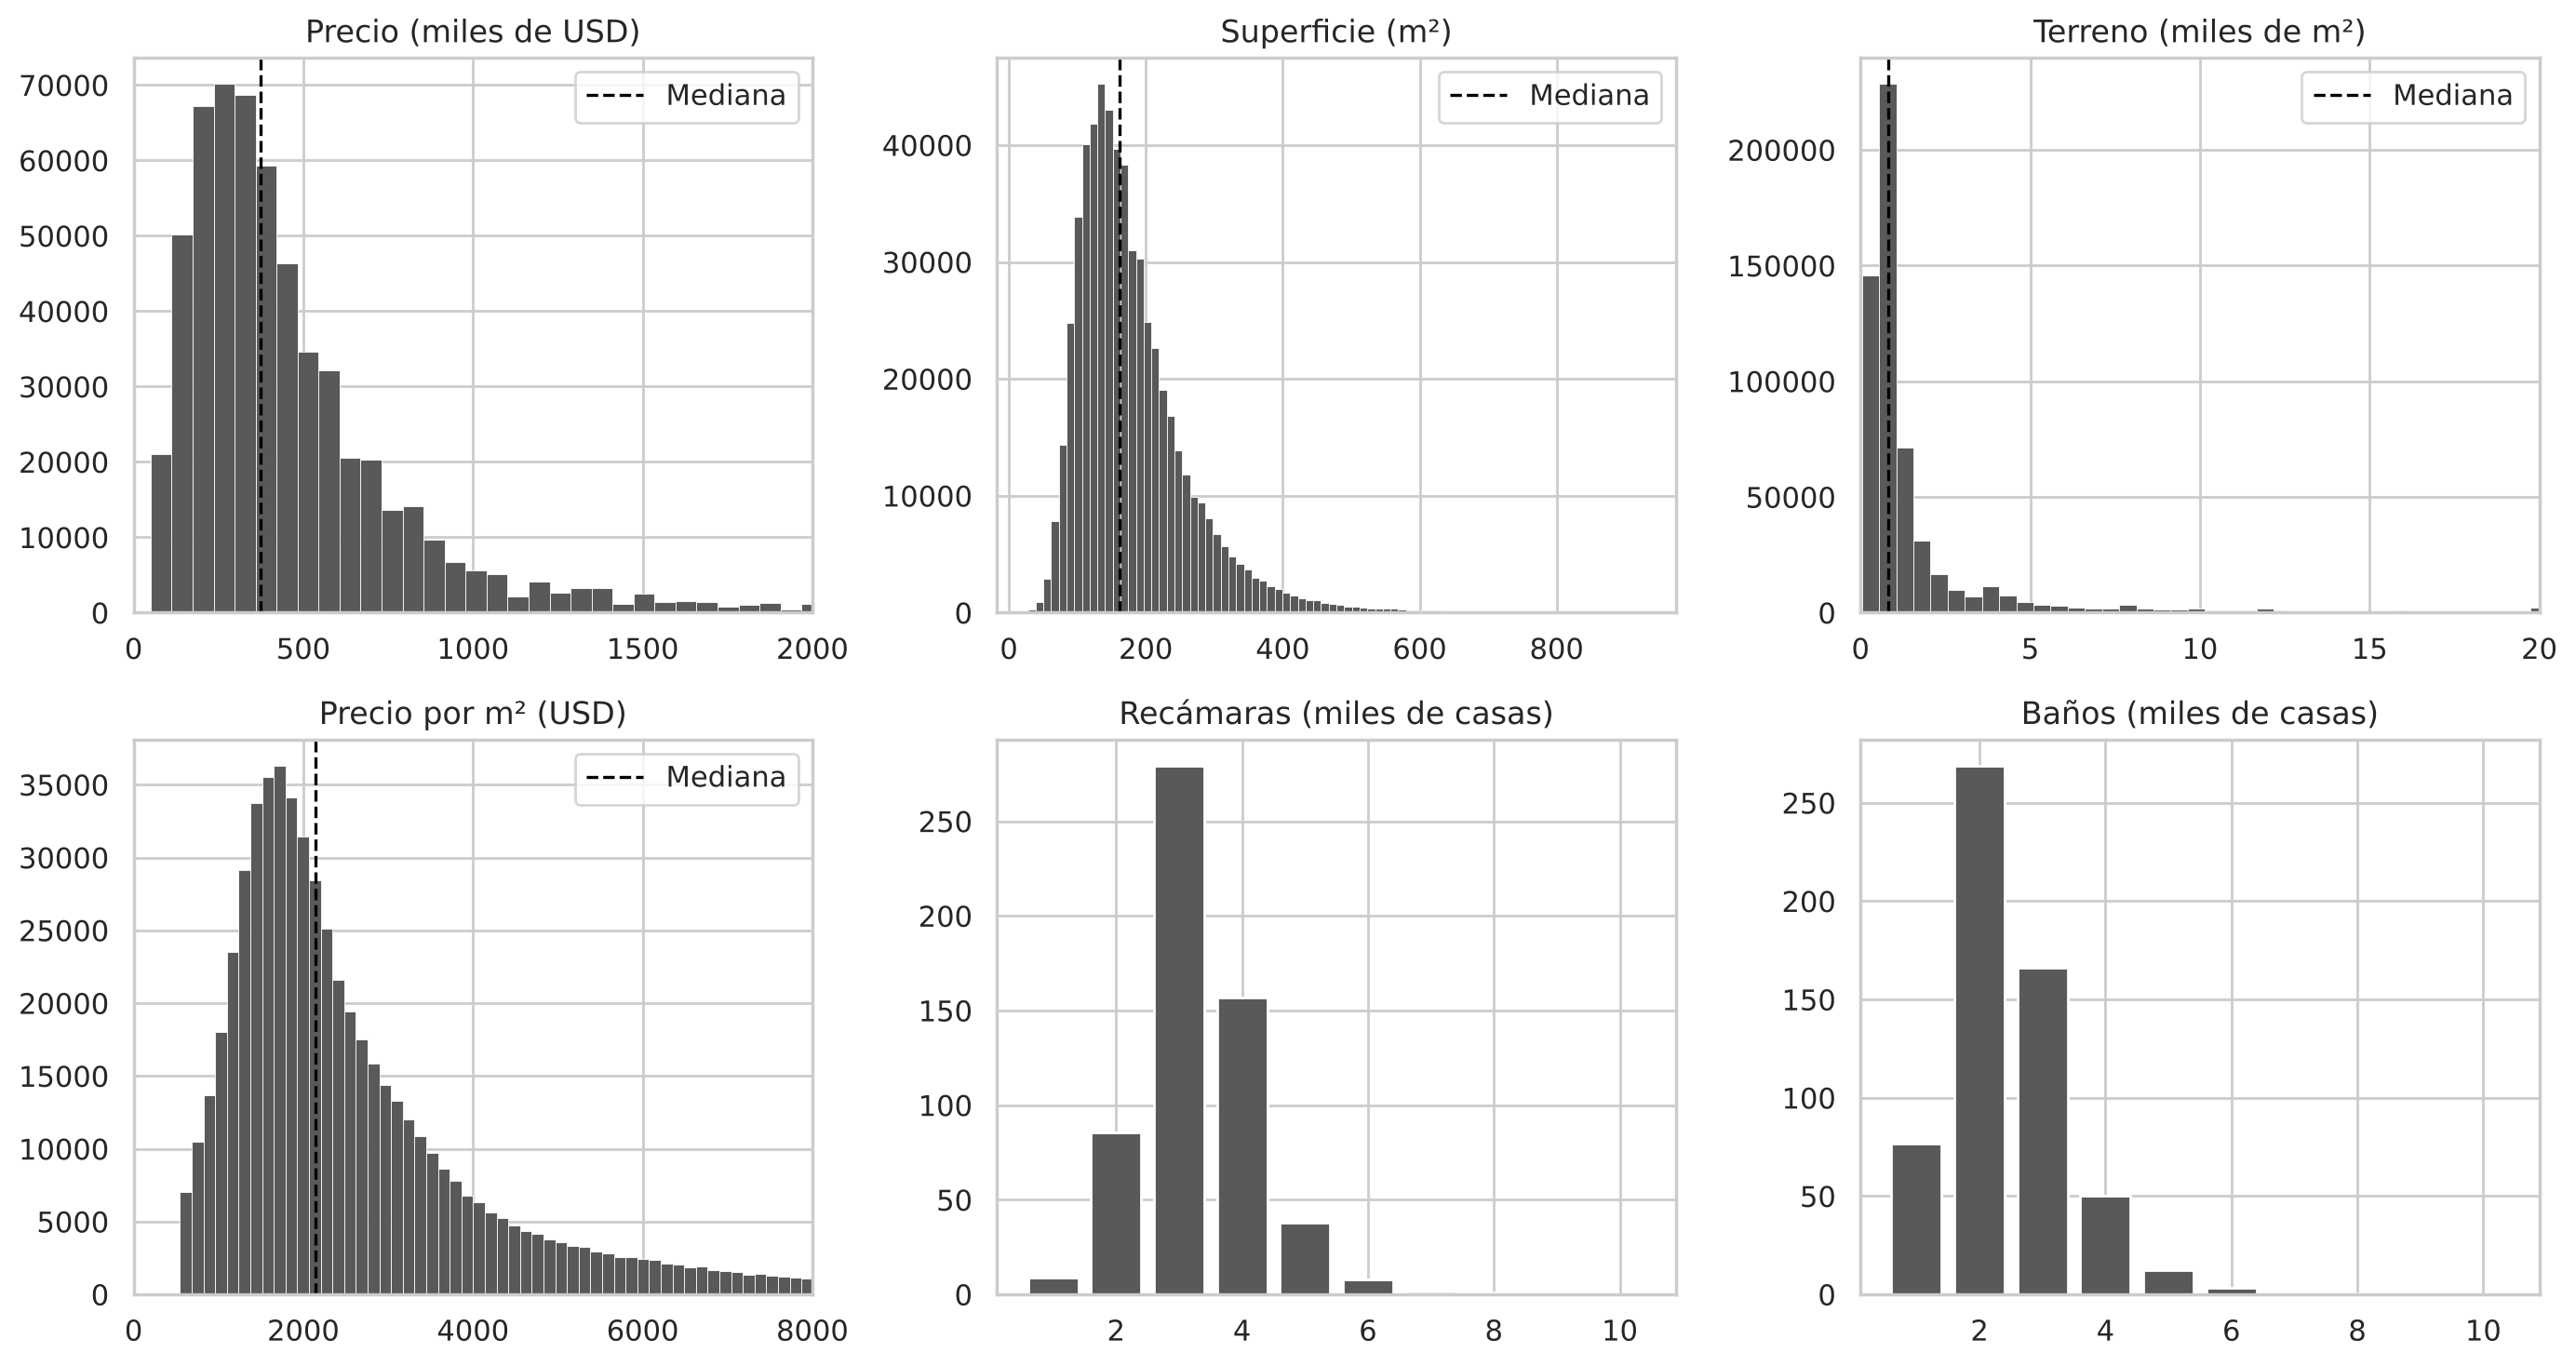

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
plots = [("price", "Precio (miles de USD)", 1000),
         ("house_size_m2", "Superficie (m²)", 1),
         ("lot_size_m2", "Terreno (miles de m²)", 1000),
         ("price_m2", "Precio por m² (USD)", 1)]
for ax, (col, title, factor) in zip(axes.flat[:4], plots):
    ax.hist(houses[col] / factor, bins=80, color="0.35", edgecolor="white", linewidth=0.3)
    ax.axvline(houses[col].median() / factor, color="black", linestyle="--", linewidth=1.2, label="Mediana")
    ax.set_title(title)
    ax.legend()
axes[0, 0].set_xlim(0, 2000)
axes[0, 2].set_xlim(0, 20)
axes[1, 0].set_xlim(0, 8000)
bed_counts = houses["bed"].value_counts().sort_index()
axes[1, 1].bar(bed_counts.index, bed_counts.values / 1000, color="0.35")
axes[1, 1].set_title("Recámaras (miles de casas)")
bath_counts = houses["bath"].value_counts().sort_index()
axes[1, 2].bar(bath_counts.index, bath_counts.values / 1000, color="0.35")
axes[1, 2].set_title("Baños (miles de casas)")
plt.tight_layout()
plt.savefig("reporte/figuras/fig1_distribuciones.pdf")
plt.savefig("reporte/figuras/fig1_distribuciones.png", dpi=150)
plt.show()

El precio, el terreno y el precio por m² tienen **asimetría positiva** (cola larga a la derecha): la mayoría de las casas son de precio medio y unas pocas son muy caras. Por eso la mediana describe mejor el centro que la media.

In [8]:
by_state = houses.groupby("state").agg(houses_sold=("price", "size"),
                                       median_price=("price", "median"),
                                       median_price_m2=("price_m2", "median"),
                                       gdp_per_capita=("gdp_per_capita", "first"),
                                       violent_crime_rate=("violent_crime_rate", "first")).sort_values("median_price", ascending=False)
big_states = by_state[by_state["houses_sold"] >= 1000]
print("Casas vendidas por estado (las ventas no están repartidas de forma pareja):")
print(by_state["houses_sold"].describe())
print("\nEstados con menos de 1,000 ventas (se excluyen de las comparaciones por estado):")
print(by_state.loc[by_state["houses_sold"] < 1000, "houses_sold"].sort_values().to_string())
print("\nEstados con 1,000 ventas o más:", len(big_states))
print("\nEstados con precio mediano más alto:")
print(big_states.head(10)[["houses_sold", "median_price", "median_price_m2"]])
print("\nEstados con precio mediano más bajo:")
print(big_states.tail(10)[["houses_sold", "median_price", "median_price_m2"]])

Casas vendidas por estado (las ventas no están repartidas de forma pareja):
count       49.0000
mean    11,831.3061
std     18,097.0718
min          3.0000
25%      1,653.0000
50%      4,216.0000
75%     16,229.0000
max     96,040.0000
Name: houses_sold, dtype: float64

Estados con menos de 1,000 ventas (se excluyen de las comparaciones por estado):
state
Vermont            3
Wyoming            7
North Dakota      14
Connecticut       44
South Dakota      55
New Hampshire     59
Indiana           71
Nebraska         111
Hawaii           126
Utah             219

Estados con 1,000 ventas o más: 39

Estados con precio mediano más alto:
                      houses_sold  median_price  median_price_m2
state                                                           
District of Columbia         1653  899,000.0000       5,049.2979
California                  96040  698,000.0000       4,701.1075
Washington                  29119  549,999.0000       3,297.7681
Oregon                       9015

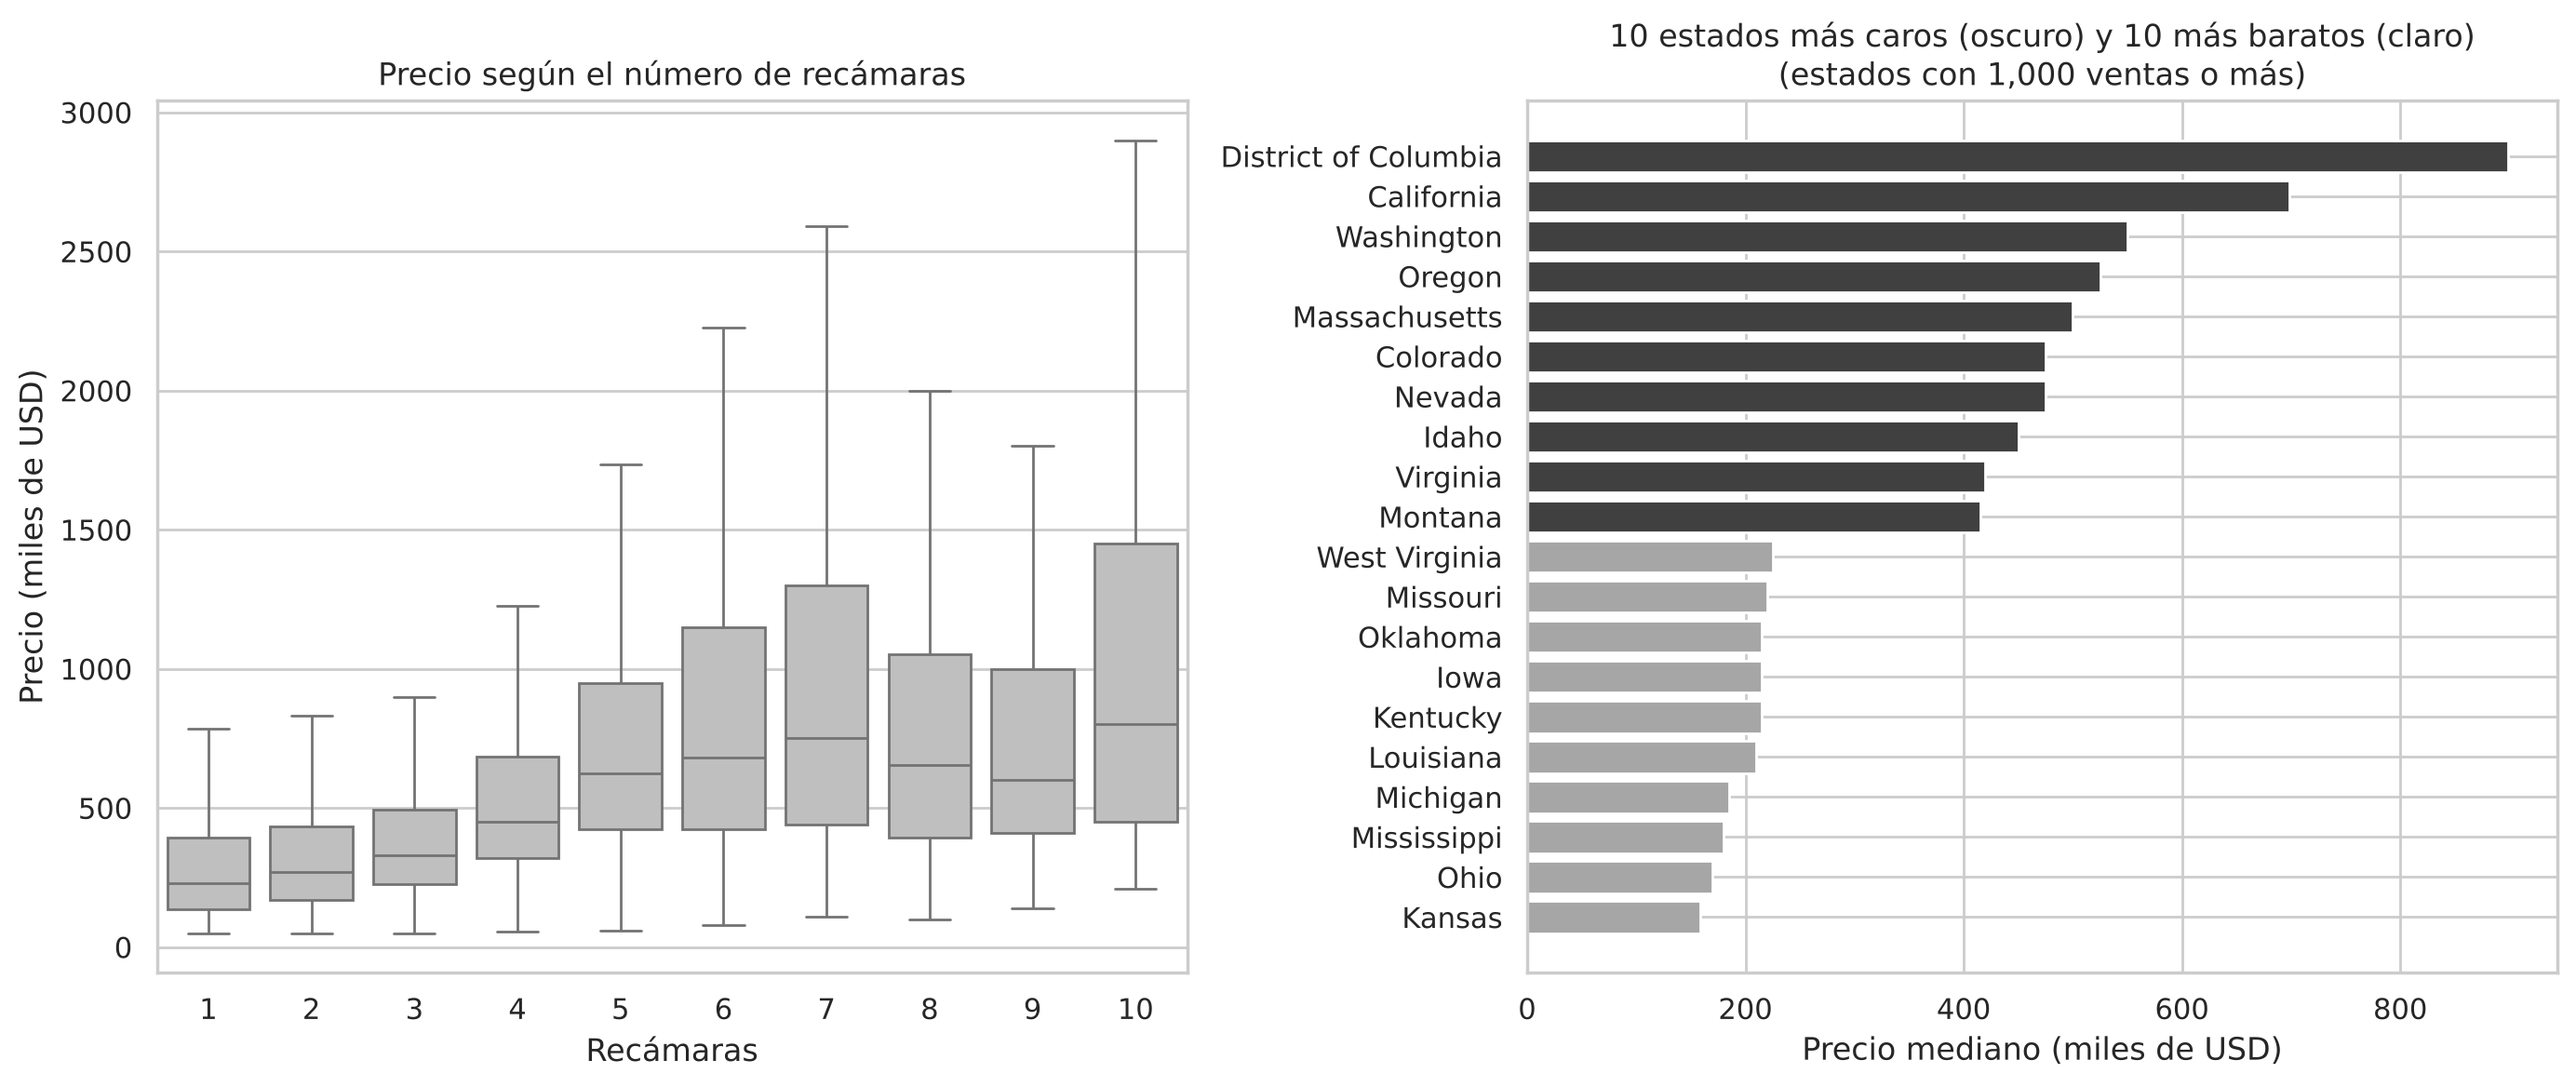

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
order = houses.groupby("bed")["price"].median().index
sns.boxplot(data=houses, x="bed", y=houses["price"] / 1000, order=order, color="0.75", showfliers=False, ax=axes[0])
axes[0].set_xlabel("Recámaras")
axes[0].set_ylabel("Precio (miles de USD)")
axes[0].set_title("Precio según el número de recámaras")

top_bottom = pd.concat([big_states.head(10), big_states.tail(10)])[::-1]
bar_colors = ["0.25" if state_name in big_states.index[:10] else "0.65" for state_name in top_bottom.index]
axes[1].barh(top_bottom.index, top_bottom["median_price"] / 1000, color=bar_colors)
axes[1].set_xlabel("Precio mediano (miles de USD)")
axes[1].set_title("10 estados más caros (oscuro) y 10 más baratos (claro)\n(estados con 1,000 ventas o más)")
plt.tight_layout()
plt.savefig("reporte/figuras/fig2_precio_recamaras_estados.pdf")
plt.savefig("reporte/figuras/fig2_precio_recamaras_estados.png", dpi=150)
plt.show()

### 2.3 Datos históricos: evolución del precio por mes

            houses_sold  median_price  median_price_m2
sale_month                                            
2021-10           10793  331,500.0000       1,926.2292
2021-11           78200  340,000.0000       1,966.1056
2021-12           92391  350,000.0000       2,025.2859
2022-01           68334  349,900.0000       2,053.5730
2022-02           75975  369,000.0000       2,159.4791
2022-03          117209  387,400.0000       2,247.1639
2022-04          130960  399,500.0000       2,265.1546
2022-05            5872  589,000.0000       3,535.2149

Octubre 2021 y mayo 2022 son meses incompletos (las ventas van del 2021-10-18 al 2022-05-06 ).
Cambio del precio mediano por m² de 2021-11 a 2022-04 (meses completos): 15.2 %


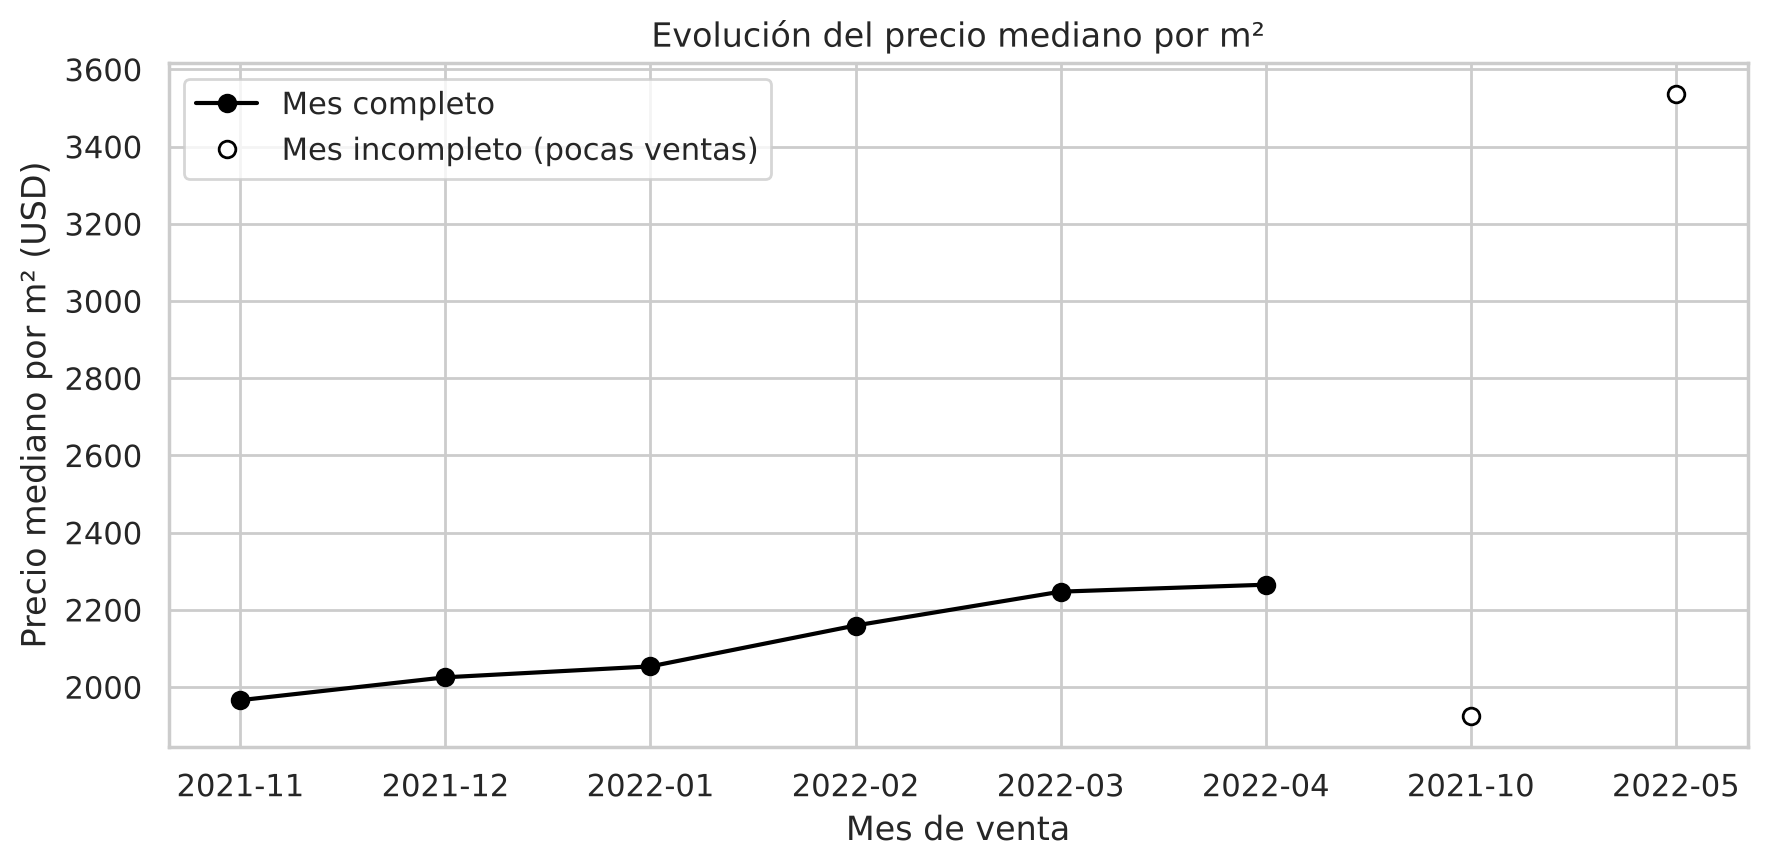

In [10]:
houses["sale_month"] = houses["sale_date"].dt.to_period("M")
monthly = houses.groupby("sale_month").agg(houses_sold=("price", "size"),
                                           median_price=("price", "median"),
                                           median_price_m2=("price_m2", "median"))
print(monthly)
full_months = monthly.iloc[1:-1]
first_m2 = full_months["median_price_m2"].iloc[0]
last_m2 = full_months["median_price_m2"].iloc[-1]
print("\nOctubre 2021 y mayo 2022 son meses incompletos (las ventas van del", houses["sale_date"].min().date(), "al", houses["sale_date"].max().date(), ").")
print(f"Cambio del precio mediano por m² de {full_months.index[0]} a {full_months.index[-1]} (meses completos): {(last_m2 / first_m2 - 1) * 100:.1f} %")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(full_months.index.astype(str), full_months["median_price_m2"], marker="o", color="black", label="Mes completo")
ax.plot([str(monthly.index[0]), str(monthly.index[-1])], monthly["median_price_m2"].iloc[[0, -1]], marker="o", linestyle="none",
        markerfacecolor="white", color="black", label="Mes incompleto (pocas ventas)")
ax.legend()
ax.set_xlabel("Mes de venta")
ax.set_ylabel("Precio mediano por m² (USD)")
ax.set_title("Evolución del precio mediano por m²")
plt.tight_layout()
plt.savefig("reporte/figuras/fig3_precio_por_mes.pdf")
plt.savefig("reporte/figuras/fig3_precio_por_mes.png", dpi=150)
plt.show()

### 2.4 Matriz de correlación
Se calculan el coeficiente de **Pearson** (relación lineal) y el de **Spearman** (relación monótona, con rangos; es más robusto a la asimetría del precio). Escala usada: |r| < 0.3 débil, 0.3 a 0.7 moderada, ≥ 0.7 fuerte.

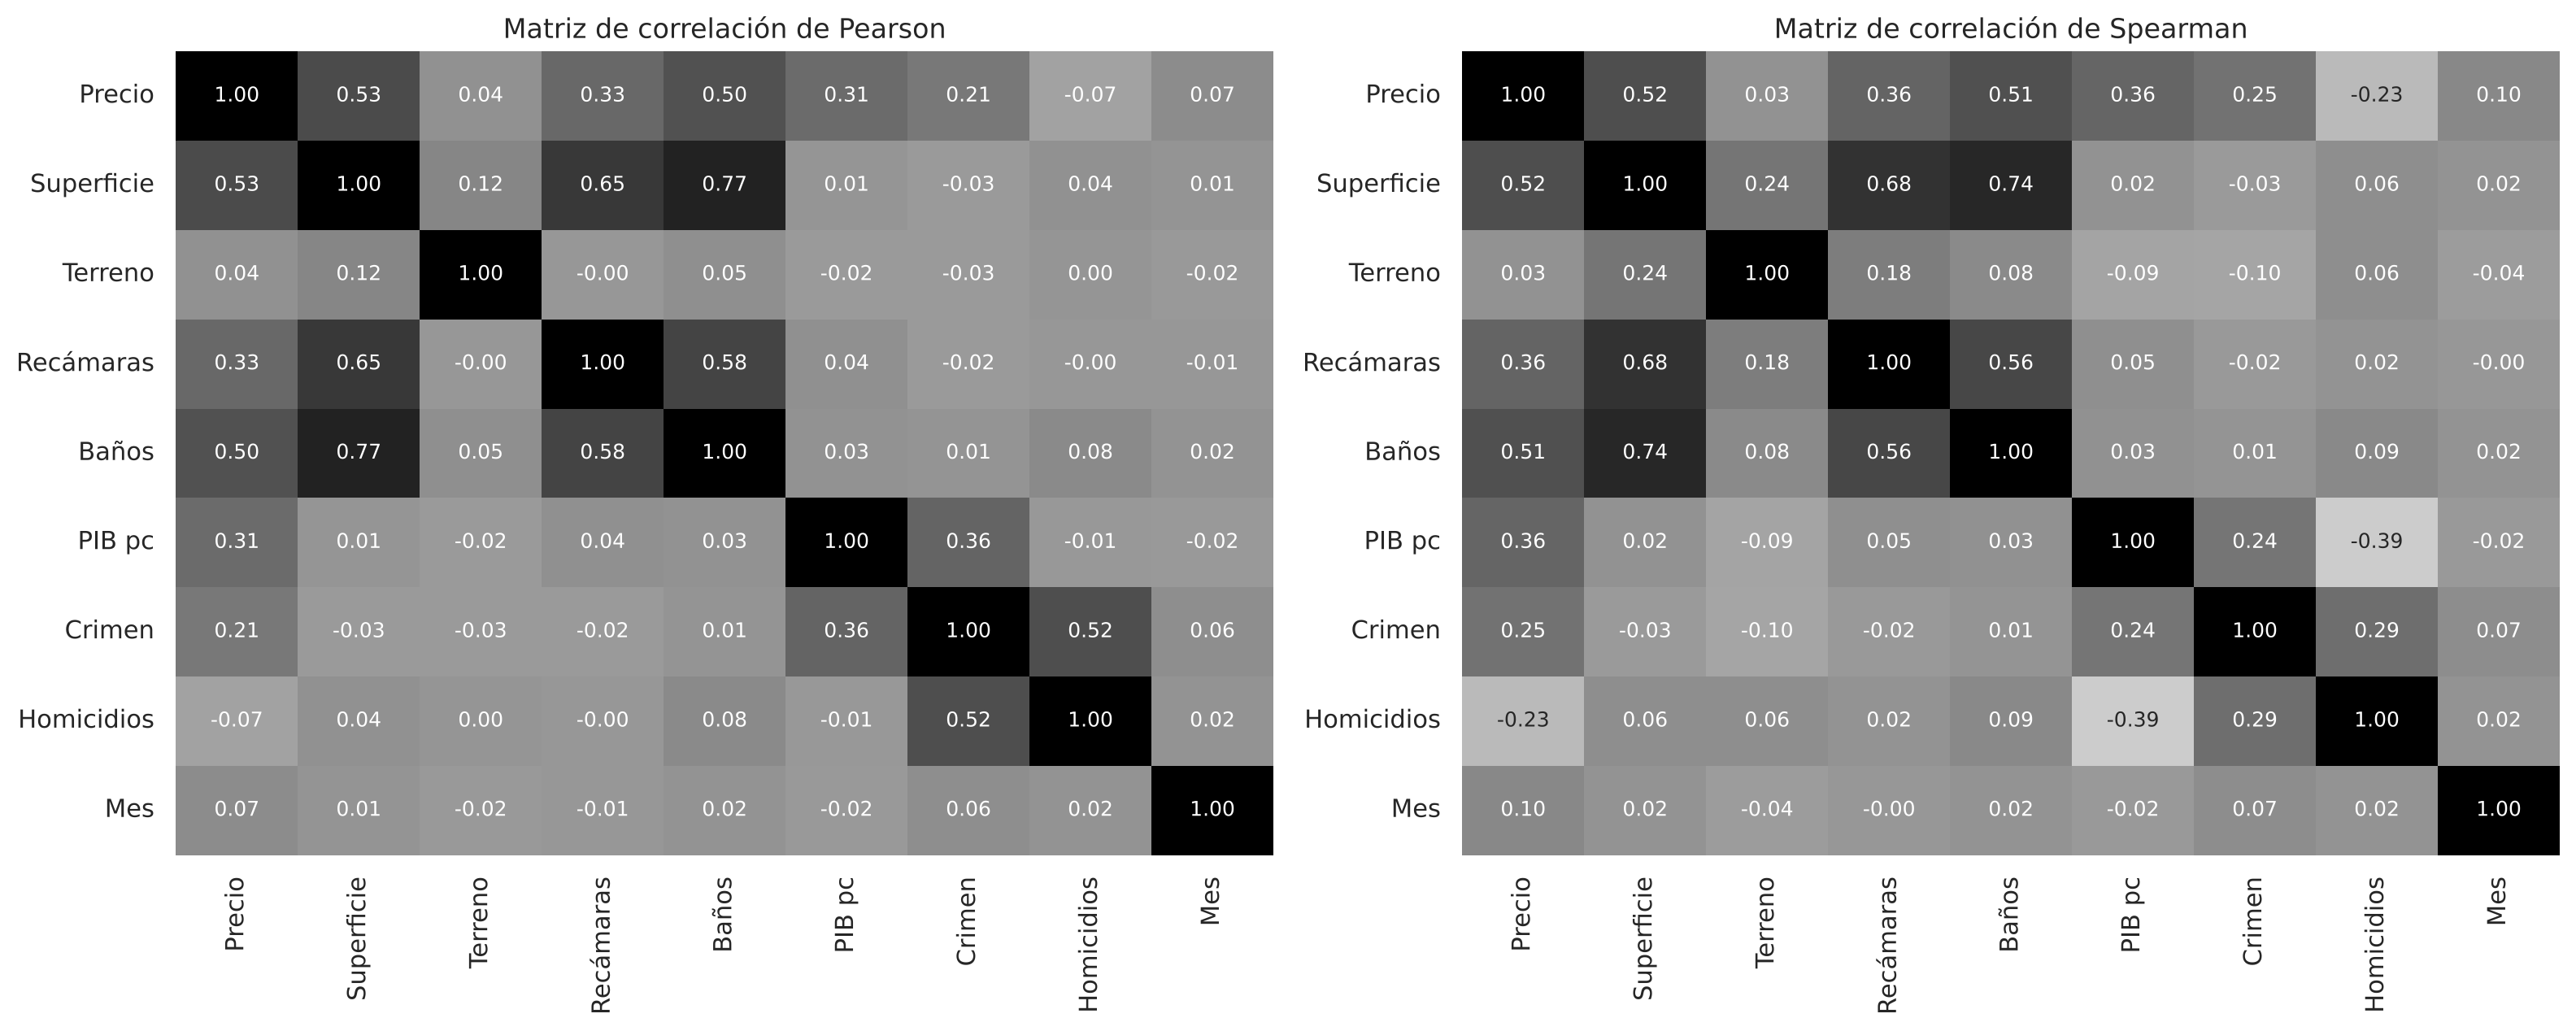

In [11]:
corr_vars = ["price", "house_size_m2", "lot_size_m2", "bed", "bath", "gdp_per_capita", "violent_crime_rate", "homicide_rate", "month_index"]
pearson = houses[corr_vars].corr(method="pearson")
spearman = houses[corr_vars].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
short = ["Precio", "Superficie", "Terreno", "Recámaras", "Baños", "PIB pc", "Crimen", "Homicidios", "Mes"]
for ax, matrix, title in zip(axes, [pearson, spearman], ["Pearson", "Spearman"]):
    sns.heatmap(matrix, annot=True, fmt=".2f", cmap="Greys", vmin=-1, vmax=1, ax=ax,
                xticklabels=short, yticklabels=short, cbar=False, annot_kws={"size": 9})
    ax.set_title(f"Matriz de correlación de {title}")
plt.tight_layout()
plt.savefig("reporte/figuras/fig4_correlacion.pdf")
plt.savefig("reporte/figuras/fig4_correlacion.png", dpi=150)
plt.show()

In [12]:
n = len(houses)
rows = []
for var in corr_vars[1:]:
    r, p_value = stats.pearsonr(houses[var], houses["price"])
    rho, p_rho = stats.spearmanr(houses[var], houses["price"])
    t_stat = r * np.sqrt(n - 2) / np.sqrt(1 - r**2)
    strength = "Fuerte" if abs(r) >= 0.7 else ("Moderada" if abs(r) >= 0.3 else "Débil")
    rows.append([labels[var], r, t_stat, p_value, rho, strength])
corr_table = pd.DataFrame(rows, columns=["Variable", "r Pearson", "t", "p-valor", "rho Spearman", "Fuerza (Pearson)"])
corr_table = corr_table.sort_values("r Pearson", key=abs, ascending=False).reset_index(drop=True)
print(f"Correlación de cada variable con el precio (n = {n:,}). Prueba: H0: rho = 0, t = r·sqrt(n-2)/sqrt(1-r²)")
corr_table

Correlación de cada variable con el precio (n = 579,734). Prueba: H0: rho = 0, t = r·sqrt(n-2)/sqrt(1-r²)


,Variable,r Pearson,t,p-valor,rho Spearman,Fuerza (Pearson)
0,Superficie (m²),0.5323,478.7296,0.0000,0.5175,Moderada
1,Baños,0.5040,444.2868,0.0000,0.5081,Moderada
2,Recámaras,0.3311,267.1929,0.0000,0.3630,Moderada
3,PIB per cápita (USD),0.3091,247.4291,0.0000,0.3577,Moderada
4,Crimen violento (por 100 mil),0.2143,167.0253,0.0000,0.2547,Débil
5,Mes de venta (0 = oct 2021),0.0750,57.2355,0.0000,0.0976,Débil
6,Homicidios (por 100 mil),-0.0736,-56.1975,0.0000,-0.2337,Débil
7,Terreno (m²),0.0375,28.5629,0.0000,0.0295,Débil


Con más de medio millón de casas, **todas** las correlaciones salen significativas (p < 0.05), incluso las muy pequeñas. Por eso se interpreta sobre todo el **tamaño** de r. La superficie y los baños tienen la relación más fuerte con el precio; recámaras, PIB per cápita y crimen tienen una relación débil a moderada.

El crimen violento tiene una correlación **positiva** con el precio. Esto no quiere decir que el crimen suba el precio: los estados con más crimen violento por habitante (por ejemplo California y Washington D.C.) también son estados grandes, urbanos y caros. Es una correlación espuria, que se explica por una tercera variable (la urbanización y el costo de vida).

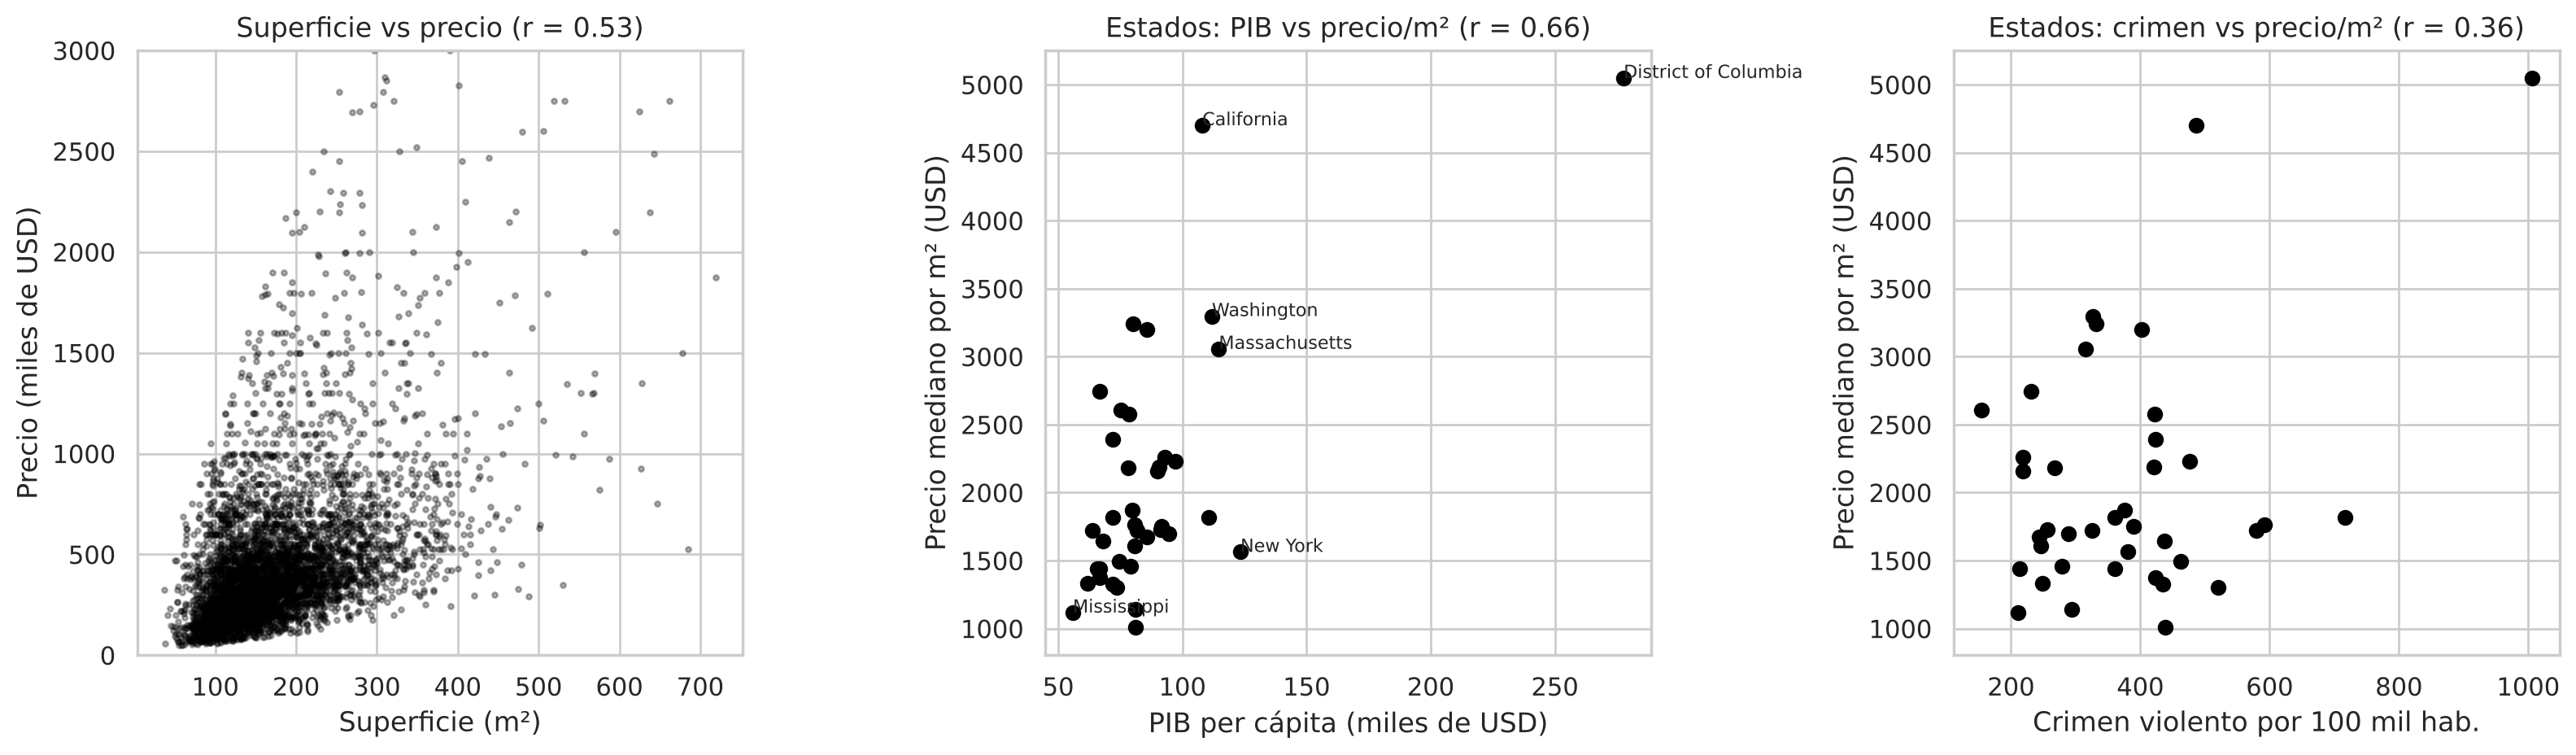

Correlación por estado (39 estados con 1,000 ventas o más), PIB per cápita vs precio mediano por m²: r = 0.6569
Correlación por estado, crimen violento vs precio mediano por m²: r = 0.3626


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
sample = houses.sample(5000, random_state=seed)
axes[0].scatter(sample["house_size_m2"], sample["price"] / 1000, s=5, alpha=0.3, color="black")
axes[0].set_xlabel("Superficie (m²)")
axes[0].set_ylabel("Precio (miles de USD)")
axes[0].set_title(f"Superficie vs precio (r = {pearson.loc['house_size_m2', 'price']:.2f})")
axes[0].set_ylim(0, 3000)
axes[1].scatter(big_states["gdp_per_capita"] / 1000, big_states["median_price_m2"], color="black")
for state_name in ["California", "District of Columbia", "Mississippi", "New York", "Massachusetts", "Washington"]:
    if state_name in big_states.index:
        axes[1].annotate(state_name, (big_states.loc[state_name, "gdp_per_capita"] / 1000, big_states.loc[state_name, "median_price_m2"]), fontsize=8)
r_state = big_states["gdp_per_capita"].corr(big_states["median_price_m2"])
axes[1].set_xlabel("PIB per cápita (miles de USD)")
axes[1].set_ylabel("Precio mediano por m² (USD)")
axes[1].set_title(f"Estados: PIB vs precio/m² (r = {r_state:.2f})")
r_crime = big_states["violent_crime_rate"].corr(big_states["median_price_m2"])
axes[2].scatter(big_states["violent_crime_rate"], big_states["median_price_m2"], color="black")
axes[2].set_xlabel("Crimen violento por 100 mil hab.")
axes[2].set_ylabel("Precio mediano por m² (USD)")
axes[2].set_title(f"Estados: crimen vs precio/m² (r = {r_crime:.2f})")
plt.tight_layout()
plt.savefig("reporte/figuras/fig5_dispersion.pdf")
plt.savefig("reporte/figuras/fig5_dispersion.png", dpi=150)
plt.show()
print(f"Correlación por estado ({len(big_states)} estados con 1,000 ventas o más), PIB per cápita vs precio mediano por m²: r = {r_state:.4f}")
print(f"Correlación por estado, crimen violento vs precio mediano por m²: r = {r_crime:.4f}")

## 3. Modelado estadístico: regresión lineal múltiple
### 3.1 Conjuntos de entrenamiento y prueba
Se separa el 80 % de las casas para entrenar y el 20 % para evaluar. Todos los modelos se evalúan con las mismas casas de prueba, que el modelo nunca vio.

**Precio por m² de la zona (dato histórico).** El valor de una casa depende mucho de su colonia. Con las ventas del conjunto de **entrenamiento** se calcula el precio mediano por m² de cada código postal (si tiene al menos 5 ventas; si no, se usa el del estado). Así cada casa tiene el precio histórico de su zona sin usar información del conjunto de prueba.

In [14]:
train, test = train_test_split(houses, test_size=0.2, random_state=seed)
train = train.copy()
test = test.copy()

zip_stats = train.groupby("zip_code")["price_m2"].agg(["median", "size"])
zip_median = zip_stats.loc[zip_stats["size"] >= 5, "median"]
state_median = train.groupby("state")["price_m2"].median()
train["zip_price_m2"] = train["zip_code"].map(zip_median).fillna(train["state"].map(state_median))
test["zip_price_m2"] = test["zip_code"].map(zip_median).fillna(test["state"].map(state_median))

print("Casas de entrenamiento:", len(train), "| Casas de prueba:", len(test))
print("Códigos postales con precio propio (5 o más ventas):", len(zip_median))
print(f"Correlación del precio por m² de la zona con el precio (entrenamiento): r = {train['zip_price_m2'].corr(train['price']):.4f}")

Casas de entrenamiento: 463787 | Casas de prueba: 115947
Códigos postales con precio propio (5 o más ventas): 9473
Correlación del precio por m² de la zona con el precio (entrenamiento): r = 0.6835


### 3.2 Modelo 1: características de la casa e indicadores del estado
$$\hat{y} = b_0 + b_1\,\text{superficie} + b_2\,\text{terreno} + b_3\,\text{recámaras} + b_4\,\text{baños} + b_5\,\text{PIB} + b_6\,\text{crimen} + b_7\,\text{mes}$$

Los coeficientes se calculan con el método de **mínimos cuadrados por matrices**: $\mathbf{b} = (\mathbf{X}'\mathbf{X})^{-1}\mathbf{X}'\mathbf{y}$, donde la primera columna de $\mathbf{X}$ es de unos (para $b_0$).

In [15]:
features_1 = ["house_size_m2", "lot_size_m2", "bed", "bath", "gdp_per_capita", "violent_crime_rate", "month_index"]
features_2 = features_1 + ["zip_price_m2"]
y_train = train["price"].to_numpy()
y_test = test["price"].to_numpy()

X1 = np.column_stack([np.ones(len(train)), train[features_1].to_numpy()])
XtX_1 = X1.T @ X1
Xty_1 = X1.T @ y_train
b_1 = np.linalg.inv(XtX_1) @ Xty_1

names_1 = ["Intercepto"] + [labels[f] for f in features_1]
print("Matriz X'X (8 x 8):")
print(pd.DataFrame(XtX_1, index=names_1, columns=names_1).map(lambda v: f"{v:.4e}"))
print("\nVector X'y:")
print(pd.Series(Xty_1, index=names_1).map(lambda v: f"{v:.4e}"))
print("\nCoeficientes b = (X'X)^-1 X'y:")
for name, value in zip(names_1, b_1):
    print(f"  {name:32s} {value:14.4f}")

Matriz X'X (8 x 8):
                               Intercepto Superficie (m²) Terreno (m²)  \
Intercepto                     4.6379e+05      8.3843e+07   9.6447e+08   
Superficie (m²)                8.3843e+07      1.8511e+10   1.9429e+11   
Terreno (m²)                   9.6447e+08      1.9429e+11   1.1065e+13   
Recámaras                      1.5256e+06      3.0017e+08   3.1645e+09   
Baños                          1.1289e+06      2.3377e+08   2.4469e+09   
PIB per cápita (USD)           4.2421e+10      7.6737e+12   8.7351e+13   
Crimen violento (por 100 mil)  1.6994e+08      3.0595e+10   3.4751e+11   
Mes de venta (0 = oct 2021)    1.7476e+06      3.1686e+08   3.5719e+09   

                                Recámaras       Baños PIB per cápita (USD)  \
Intercepto                     1.5256e+06  1.1289e+06           4.2421e+10   
Superficie (m²)                3.0017e+08  2.3377e+08           7.6737e+12   
Terreno (m²)                   3.1645e+09  2.4469e+09           8.7351e+13   
R

In [16]:
model_1 = sm.OLS(y_train, sm.add_constant(train[features_1])).fit()
print("Comprobación con statsmodels (mismos coeficientes):", np.allclose(model_1.params.to_numpy(), b_1))
print(model_1.summary())

Comprobación con statsmodels (mismos coeficientes): True
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.417
Model:                            OLS   Adj. R-squared:                  0.417
Method:                 Least Squares   F-statistic:                 4.740e+04
Date:                Wed, 25 Nov 2026   Prob (F-statistic):               0.00
Time:                        04:37:26   Log-Likelihood:            -6.5273e+06
No. Observations:              463787   AIC:                         1.305e+07
Df Residuals:                  463779   BIC:                         1.305e+07
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------

### 3.3 Modelo 2: se agrega el precio por m² de la zona

In [17]:
X2 = np.column_stack([np.ones(len(train)), train[features_2].to_numpy()])
XtX_2 = X2.T @ X2
Xty_2 = X2.T @ y_train
b_2 = np.linalg.inv(XtX_2) @ Xty_2
names_2 = ["Intercepto"] + [labels[f] for f in features_2]

model_2 = sm.OLS(y_train, sm.add_constant(train[features_2])).fit()
print("Comprobación con statsmodels (mismos coeficientes):", np.allclose(model_2.params.to_numpy(), b_2))

coef_table = pd.DataFrame({"Coeficiente": model_2.params.to_numpy(),
                           "Error est.": model_2.bse.to_numpy(),
                           "t": model_2.tvalues.to_numpy(),
                           "p-valor": model_2.pvalues.to_numpy()}, index=names_2)
coef_table["Significativo"] = np.where(coef_table["p-valor"] < alpha, "Sí", "No")
print(f"R² = {model_2.rsquared:.4f} | R² ajustado = {model_2.rsquared_adj:.4f} | F = {model_2.fvalue:,.1f}")
coef_table

Comprobación con statsmodels (mismos coeficientes): True
R² = 0.7531 | R² ajustado = 0.7531 | F = 176,790.6


,Coeficiente,Error est.,t,p-valor,Significativo
Intercepto,"-481,280.8266","2,071.5078",-232.3336,0.0000,Sí
Superficie (m²),"2,215.9234",6.0377,367.0137,0.0000,Sí
Terreno (m²),0.8347,0.0687,12.1481,0.0000,Sí
Recámaras,"-6,302.9994",420.9334,-14.9739,0.0000,Sí
Baños,"42,792.2709",486.2964,87.9963,0.0000,Sí
PIB per cápita (USD),0.1480,0.0194,7.6387,0.0000,Sí
Crimen violento (por 100 mil),-39.5694,3.1876,-12.4136,0.0000,Sí
Mes de venta (0 = oct 2021),"6,504.6741",162.9746,39.9122,0.0000,Sí
Precio por m² de la zona (USD),170.2703,0.2143,794.3864,0.0000,Sí


In [18]:
vif = pd.DataFrame({"Variable": [labels[f] for f in features_2],
                    "VIF": [variance_inflation_factor(sm.add_constant(train[features_2]).to_numpy(), i + 1) for i in range(len(features_2))]})
print("Factor de inflación de la varianza (VIF > 10 indica multicolinealidad grave):")
vif

Factor de inflación de la varianza (VIF > 10 indica multicolinealidad grave):


,Variable,VIF
0,Superficie (m²),2.9399
1,Terreno (m²),1.0283
2,Recámaras,1.8004
3,Baños,2.5434
4,PIB per cápita (USD),1.3466
5,Crimen violento (por 100 mil),1.2140
6,Mes de venta (0 = oct 2021),1.0099
7,Precio por m² de la zona (USD),1.3473


In [19]:
def metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {"MSE": mse, "RMSE": np.sqrt(mse), "MAE": mean_absolute_error(y_true, y_pred), "R²": r2_score(y_true, y_pred)}

pred_lr1 = np.column_stack([np.ones(len(test)), test[features_1].to_numpy()]) @ b_1
pred_lr2 = np.column_stack([np.ones(len(test)), test[features_2].to_numpy()]) @ b_2
linear_results = pd.DataFrame([metrics(y_test, pred_lr1), metrics(y_test, pred_lr2)],
                              index=["Regresión lineal 1 (sin zona)", "Regresión lineal 2 (con zona)"])
print("Métricas en el conjunto de prueba (USD):")
linear_results

Métricas en el conjunto de prueba (USD):


,MSE,RMSE,MAE,R²
Regresión lineal 1 (sin zona),"96,942,543,937.1459","311,355.9762","195,172.4919",0.4192
Regresión lineal 2 (con zona),"41,728,558,176.1715","204,275.6916","116,808.2338",0.7500


**Interpretación.** El modelo 1 solo explica cerca del 40 % de la variación del precio: con las características de la casa y los indicadores del estado no basta, porque la ubicación dentro del estado pesa mucho. Al agregar el precio por m² de la zona, el R² sube a cerca de 0.75 y el error medio baja mucho. Las variables tienen VIF bajo, así que no hay multicolinealidad grave.

Una limitación de la regresión lineal es que suma los efectos: 1 m² extra vale lo mismo en Mississippi que en Manhattan. En realidad el valor del m² cambia según la zona. Los modelos de *machine learning* de la siguiente fase pueden captar esas interacciones.

## 4. Modelado predictivo con machine learning
Se entrenan cinco modelos con las mismas 8 variables del modelo lineal 2:
- **K vecinos más cercanos (KNN)**: promedia el precio de las 10 casas más parecidas (con variables estandarizadas).
- **Árbol de decisión**: divide las casas en grupos con reglas del tipo "si superficie > 150 m²...".
- **Random Forest**: promedio de 100 árboles, cada uno entrenado con una muestra distinta.
- **XGBoost** (*gradient boosting*): 500 árboles pequeños, cada uno corrige los errores de los anteriores.
- **Red neuronal (perceptrón multicapa)**: dos capas ocultas de 64 y 32 neuronas.

In [20]:
scaler = StandardScaler().fit(train[features_2])
X_train_scaled = scaler.transform(train[features_2])
X_test_scaled = scaler.transform(test[features_2])

ml_models = {
    "KNN (k = 10)": (KNeighborsRegressor(n_neighbors=10, n_jobs=-1), True),
    "Árbol de decisión": (DecisionTreeRegressor(max_depth=12, min_samples_leaf=20, random_state=seed), False),
    "Random Forest": (RandomForestRegressor(n_estimators=100, max_depth=20, min_samples_leaf=5, n_jobs=-1, random_state=seed), False),
    "XGBoost": (XGBRegressor(n_estimators=500, max_depth=8, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, n_jobs=-1, random_state=seed), False),
    "Red neuronal (MLP)": (MLPRegressor(hidden_layer_sizes=(64, 32), learning_rate_init=0.001, max_iter=60, early_stopping=True, random_state=seed), True),
}

predictions = {"Regresión lineal 1 (sin zona)": pred_lr1, "Regresión lineal 2 (con zona)": pred_lr2}
train_seconds = {"Regresión lineal 1 (sin zona)": np.nan, "Regresión lineal 2 (con zona)": np.nan}
for name, (model, scaled) in ml_models.items():
    start = time.time()
    if scaled:
        model.fit(X_train_scaled, y_train)
        predictions[name] = model.predict(X_test_scaled)
    else:
        model.fit(train[features_2], y_train)
        predictions[name] = model.predict(test[features_2])
    train_seconds[name] = time.time() - start
    print(f"{name}: listo en {train_seconds[name]:.1f} s, R² de prueba = {r2_score(y_test, predictions[name]):.4f}")

KNN (k = 10): listo en 10.3 s, R² de prueba = 0.8450


Árbol de decisión: listo en 1.6 s, R² de prueba = 0.8470


Random Forest: listo en 37.2 s, R² de prueba = 0.8693


XGBoost: listo en 6.4 s, R² de prueba = 0.8727


/usr/local/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (60) reached and the optimization hasn't converged yet.
  warnings.warn(


Red neuronal (MLP): listo en 135.6 s, R² de prueba = 0.8493


## 5. Evaluación y comparación de modelos

In [21]:
results = pd.DataFrame({name: metrics(y_test, pred) for name, pred in predictions.items()}).T
results["Tiempo (s)"] = pd.Series(train_seconds)
results = results.sort_values("R²", ascending=False)
results.to_csv("modelos/metricas_modelos.csv", index_label="Modelo", encoding="utf-8")
best_name = results.index[0]
print("Comparación en el conjunto de prueba (", len(test), "casas ). MSE en USD², RMSE y MAE en USD.")
print("Mejor modelo:", best_name)
results.style.format({"MSE": "{:.3e}", "RMSE": "{:,.0f}", "MAE": "{:,.0f}", "R²": "{:.4f}", "Tiempo (s)": "{:.1f}"})

Comparación en el conjunto de prueba ( 115947 casas ). MSE en USD², RMSE y MAE en USD.
Mejor modelo: XGBoost


,MSE,RMSE,MAE,R²,Tiempo (s)
XGBoost,2.124e+10,"145,737","78,284",0.8727,6.4
Random Forest,2.181e+10,"147,686","78,220",0.8693,37.2
Red neuronal (MLP),2.515e+10,"158,581","86,691",0.8493,135.6
Árbol de decisión,2.553e+10,"159,784","85,531",0.8470,1.6
KNN (k = 10),2.588e+10,"160,863","86,531",0.8450,10.3
Regresión lineal 2 (con zona),4.173e+10,"204,276","116,808",0.7500,nan
Regresión lineal 1 (sin zona),9.694e+10,"311,356","195,172",0.4192,nan


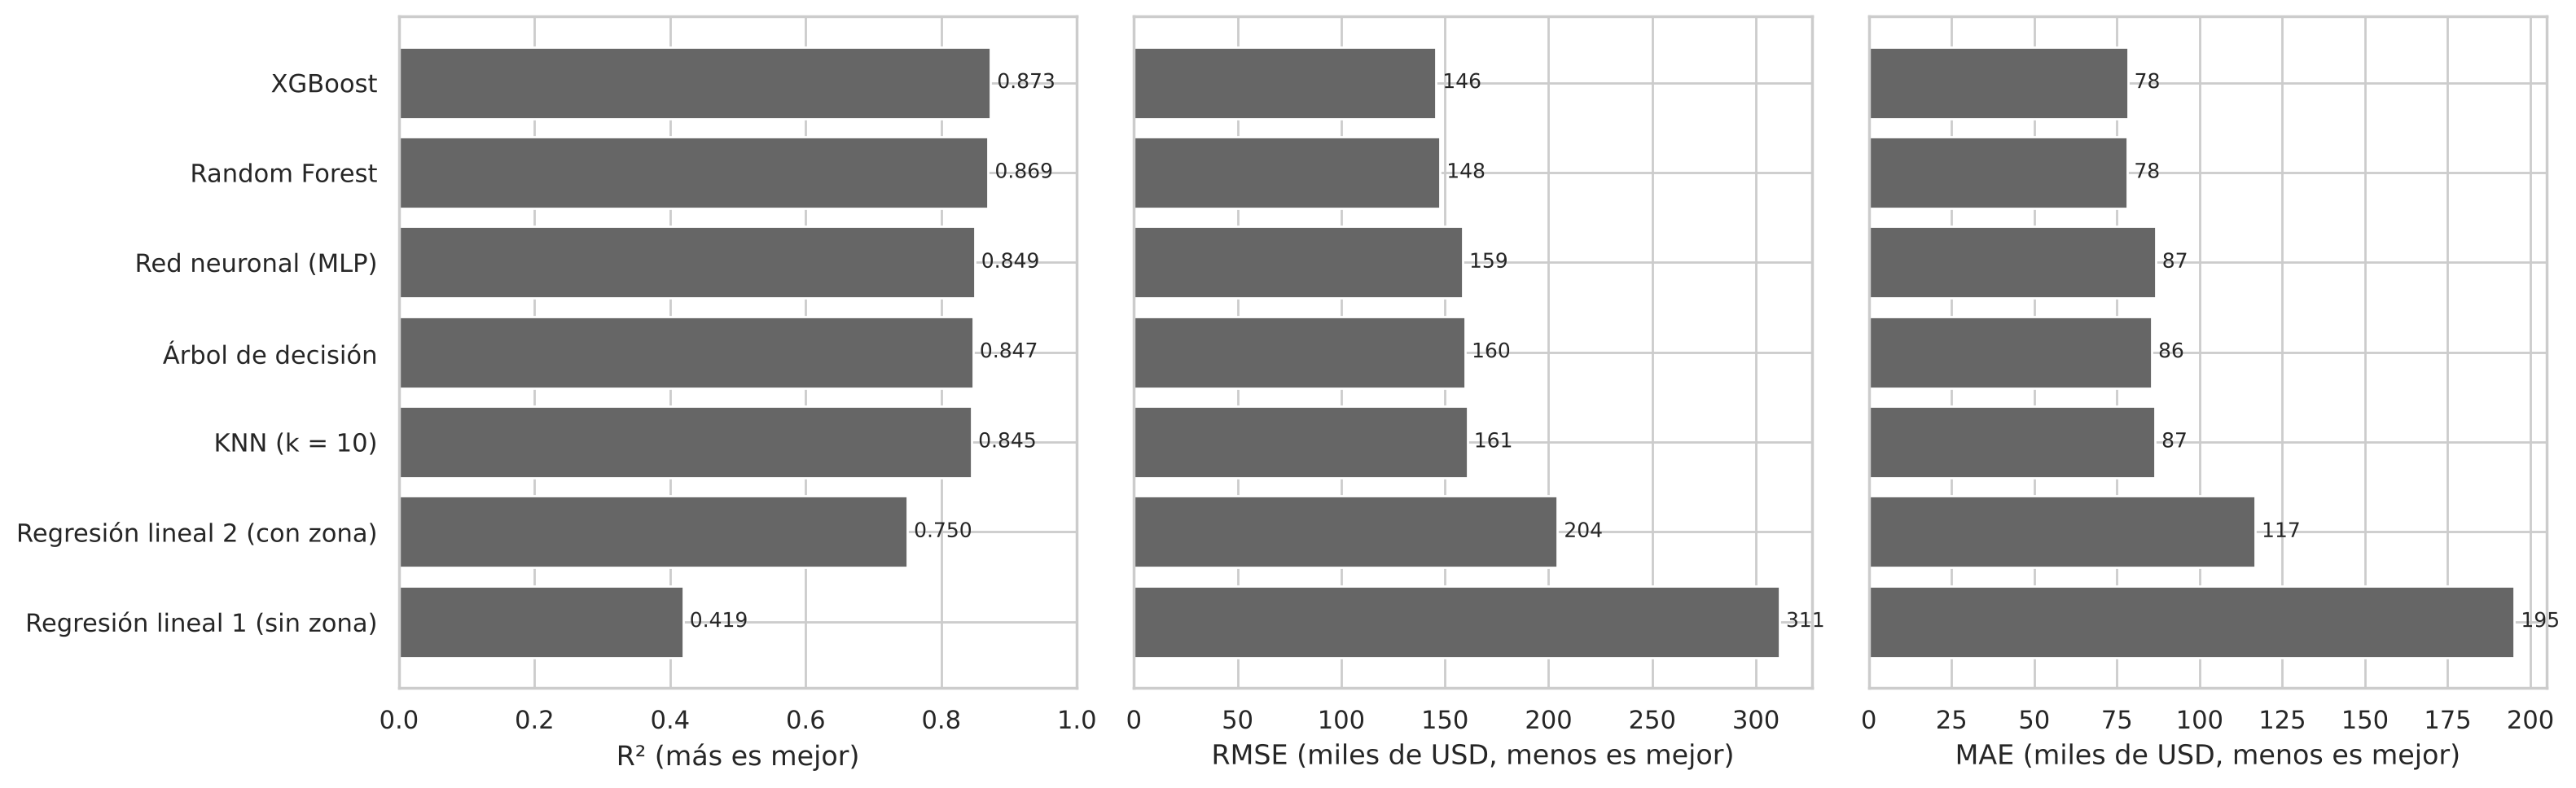

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
order_plot = results.index[::-1]
axes[0].barh(order_plot, results.loc[order_plot, "R²"], color="0.4")
axes[0].set_xlabel("R² (más es mejor)")
axes[0].set_xlim(0, 1)
axes[1].barh(order_plot, results.loc[order_plot, "RMSE"] / 1000, color="0.4")
axes[1].set_xlabel("RMSE (miles de USD, menos es mejor)")
axes[1].set_yticklabels([])
axes[2].barh(order_plot, results.loc[order_plot, "MAE"] / 1000, color="0.4")
axes[2].set_xlabel("MAE (miles de USD, menos es mejor)")
axes[2].set_yticklabels([])
for ax, col, factor, fmt in [(axes[0], "R²", 1, "{:.3f}"), (axes[1], "RMSE", 1000, "{:.0f}"), (axes[2], "MAE", 1000, "{:.0f}")]:
    for i, name in enumerate(order_plot):
        value = results.loc[name, col] / factor
        ax.text(value, i, " " + fmt.format(value), va="center", fontsize=9)
plt.tight_layout()
plt.savefig("reporte/figuras/fig6_comparacion_modelos.pdf")
plt.savefig("reporte/figuras/fig6_comparacion_modelos.png", dpi=150)
plt.show()

Importancia de las variables en XGBoost (ganancia relativa):
Precio por m² de la zona (USD)    38.82 %
Superficie (m²)                   23.81 %
Baños                             19.42 %
PIB per cápita (USD)               7.83 %
Crimen violento (por 100 mil)      3.85 %
Recámaras                          3.03 %
Terreno (m²)                       2.03 %
Mes de venta (0 = oct 2021)         1.2 %
dtype: str


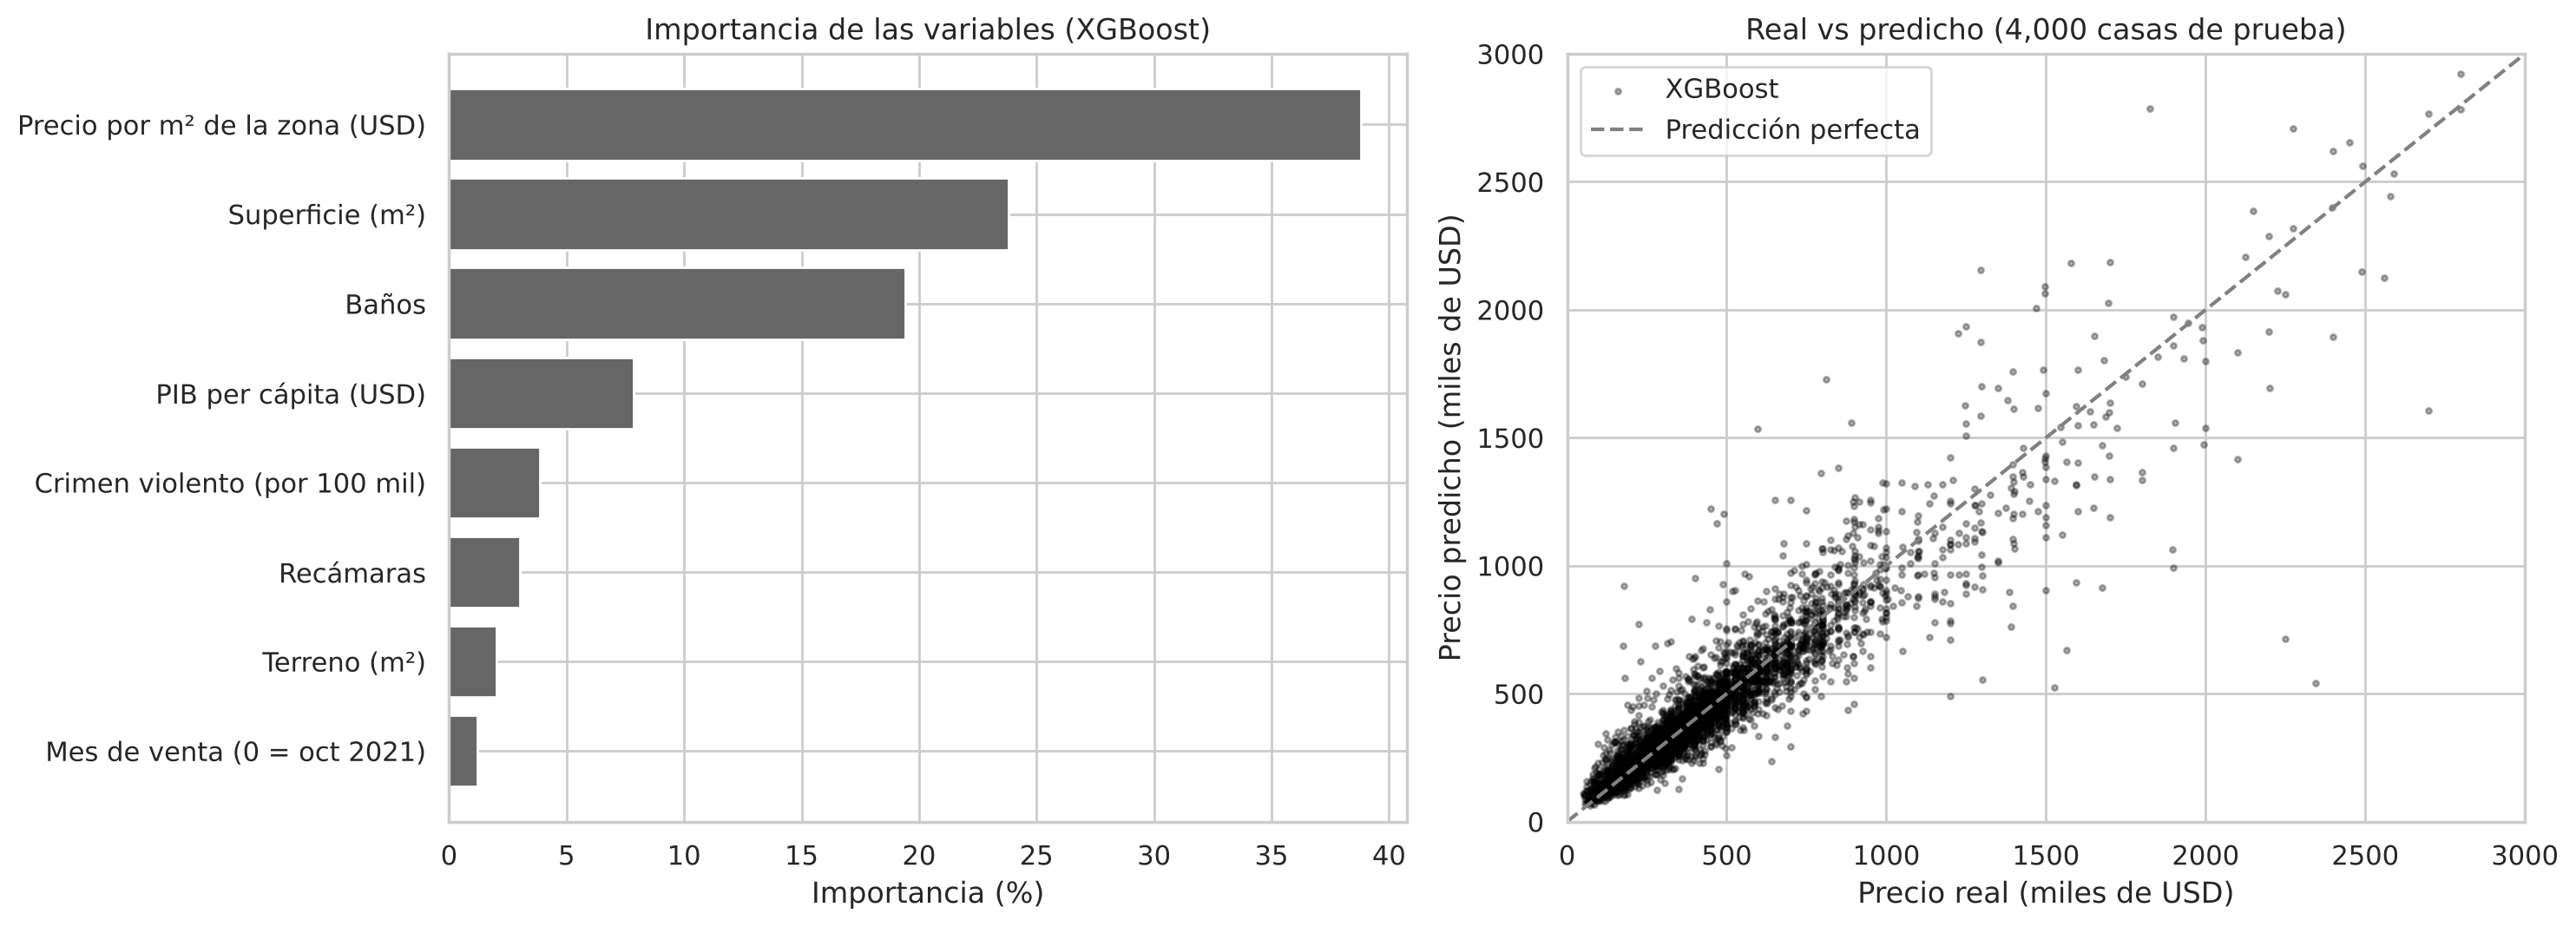

In [23]:
best_model = ml_models["XGBoost"][0]
importance = pd.Series(best_model.feature_importances_, index=[labels[f] for f in features_2]).sort_values()
print("Importancia de las variables en XGBoost (ganancia relativa):")
print((importance[::-1] * 100).round(2).astype(str) + " %")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
axes[0].barh(importance.index, importance.values * 100, color="0.4")
axes[0].set_xlabel("Importancia (%)")
axes[0].set_title("Importancia de las variables (XGBoost)")
sample_idx = np.random.default_rng(seed).choice(len(test), 4000, replace=False)
axes[1].scatter(y_test[sample_idx] / 1000, predictions["XGBoost"][sample_idx] / 1000, s=5, alpha=0.3, color="black", label="XGBoost")
axes[1].plot([0, 3000], [0, 3000], color="0.5", linestyle="--", label="Predicción perfecta")
axes[1].set_xlim(0, 3000)
axes[1].set_ylim(0, 3000)
axes[1].set_xlabel("Precio real (miles de USD)")
axes[1].set_ylabel("Precio predicho (miles de USD)")
axes[1].set_title("Real vs predicho (4,000 casas de prueba)")
axes[1].legend()
plt.tight_layout()
plt.savefig("reporte/figuras/fig7_importancia_real_vs_predicho.pdf")
plt.savefig("reporte/figuras/fig7_importancia_real_vs_predicho.png", dpi=150)
plt.show()

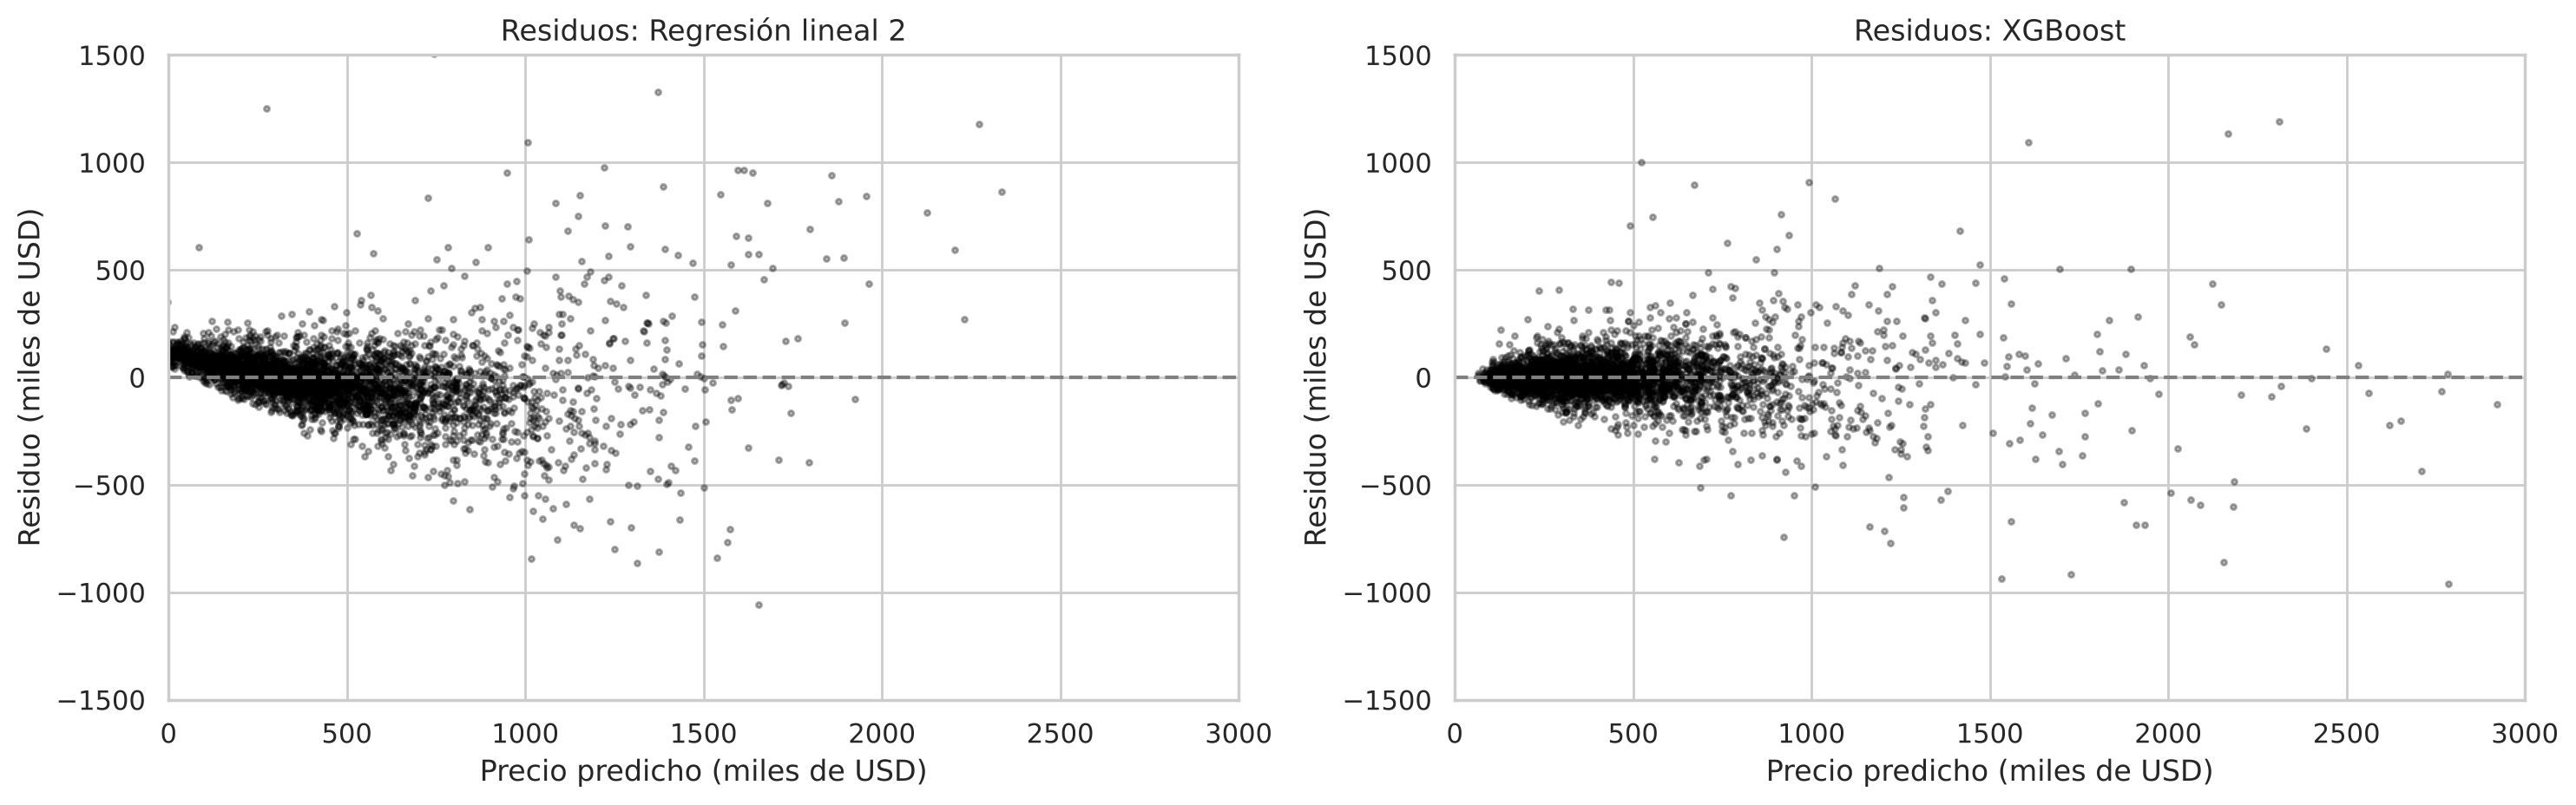

Error de XGBoost por rango de precio real:
               houses          MAE  median_pct_error
band                                                
< 200 mil       20842  43,996.7129           20.2418
200 a 400 mil   44189  47,043.3634           11.3834
400 a 800 mil   37100  78,471.1298           10.4514
> 800 mil       13816 229,421.3180           12.8177

Error porcentual mediano de XGBoost: 12.2 %
Error porcentual mediano de la regresión lineal 2: 19.9 %


In [24]:
residuals_lr = y_test - pred_lr2
residuals_xgb = y_test - predictions["XGBoost"]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for ax, res, pred, title in [(axes[0], residuals_lr, pred_lr2, "Regresión lineal 2"), (axes[1], residuals_xgb, predictions["XGBoost"], "XGBoost")]:
    ax.scatter(pred[sample_idx] / 1000, res[sample_idx] / 1000, s=5, alpha=0.3, color="black")
    ax.axhline(0, color="0.5", linestyle="--")
    ax.set_xlim(0, 3000)
    ax.set_ylim(-1500, 1500)
    ax.set_xlabel("Precio predicho (miles de USD)")
    ax.set_ylabel("Residuo (miles de USD)")
    ax.set_title(f"Residuos: {title}")
plt.tight_layout()
plt.savefig("reporte/figuras/fig8_residuos.pdf")
plt.savefig("reporte/figuras/fig8_residuos.png", dpi=150)
plt.show()

price_band = pd.cut(y_test, [0, 200_000, 400_000, 800_000, 5_000_001], labels=["< 200 mil", "200 a 400 mil", "400 a 800 mil", "> 800 mil"])
error_band = pd.DataFrame({"band": price_band, "abs_error": np.abs(residuals_xgb), "pct_error": np.abs(residuals_xgb) / y_test * 100})
print("Error de XGBoost por rango de precio real:")
print(error_band.groupby("band", observed=True).agg(houses=("abs_error", "size"), MAE=("abs_error", "mean"), median_pct_error=("pct_error", "median")))
print(f"\nError porcentual mediano de XGBoost: {np.median(np.abs(residuals_xgb) / y_test * 100):.1f} %")
print(f"Error porcentual mediano de la regresión lineal 2: {np.median(np.abs(residuals_lr) / y_test * 100):.1f} %")

## 6. Ejemplo de predicción y archivos para el dashboard
Casa de ejemplo: 180 m² de construcción, terreno de 600 m², 3 recámaras y 2 baños, vendida en mayo de 2022 en Austin, Texas (código postal 78745).

In [25]:
example_zip = "78745"
example = pd.DataFrame([{"house_size_m2": 180, "lot_size_m2": 600, "bed": 3, "bath": 2,
                         "gdp_per_capita": state_data.set_index("state").loc["Texas", "gdp_per_capita"],
                         "violent_crime_rate": state_data.set_index("state").loc["Texas", "violent_crime_rate"],
                         "month_index": 7,
                         "zip_price_m2": zip_median.get(example_zip, state_median["Texas"])}])
print(f"Precio por m² de la zona {example_zip}: {example['zip_price_m2'].iloc[0]:,.0f} USD")
print(f"Regresión lineal 2: {(np.r_[1, example[features_2].iloc[0].to_numpy()] @ b_2):,.0f} USD")
print(f"XGBoost:            {best_model.predict(example[features_2])[0]:,.0f} USD")

Precio por m² de la zona 78745: 1,753 USD
Regresión lineal 2: 326,896 USD
XGBoost:            324,496 USD


In [26]:
best_model.save_model("modelos/modelo_xgboost.json")
pd.DataFrame({"zip_code": zip_median.index, "zip_price_m2": zip_median.values}).to_csv("modelos/precio_m2_zona.csv", index=False)
pd.DataFrame({"state": state_median.index, "state_price_m2": state_median.values}).to_csv("modelos/precio_m2_estado.csv", index=False)
pd.DataFrame({"variable": ["intercept"] + features_2, "coefficient": b_2}).to_csv("modelos/coeficientes_regresion.csv", index=False)
print("Archivos guardados en modelos/ para el dashboard: modelo_xgboost.json, precio_m2_zona.csv,")
print("precio_m2_estado.csv, coeficientes_regresion.csv y metricas_modelos.csv")

Archivos guardados en modelos/ para el dashboard: modelo_xgboost.json, precio_m2_zona.csv,
precio_m2_estado.csv, coeficientes_regresion.csv y metricas_modelos.csv


## Conclusiones
1. **Factores más influyentes.** La superficie (r ≈ 0.53) y el número de baños (r ≈ 0.50) son las características con mayor correlación con el precio; las recámaras tienen una relación moderada y el terreno casi nula. Por estado (39 estados con 1,000 ventas o más), el PIB per cápita tiene una correlación moderada con el precio mediano por m² (r ≈ 0.66). El factor más fuerte de todos es la **ubicación**: el precio histórico por m² de la zona tiene r ≈ 0.68 con el precio.
2. **Regresión lineal.** Sin la zona explica cerca del 40 % de la variación (R² ≈ 0.42); con la zona llega a R² ≈ 0.75. Todos los coeficientes son significativos por el gran tamaño de muestra.
3. **Machine learning.** XGBoost es el mejor modelo (R² ≈ 0.87, MAE ≈ 78 mil USD), seguido de Random Forest. Superan a la regresión lineal porque captan que el valor de un m² depende de la zona.
4. **Recomendación.** Usar XGBoost para estimar precios, con la regresión lineal como modelo explicativo. Para mejorar: agregar coordenadas, acceso a escuelas, transporte y hospitales, y datos de más años.